# Distributions and the forward builders

<div class="alert alert-info">

**Summary**

This lesson constructs the portfolio stage of the portfolio–consumption model and reads how the package carries the distribution of the state through it. You will read the declaration of the stage's two shocks and ask the stage for its [[forward_builder|forward builders]], the signature and card of the second, the law of motion it owns and the expectation the [[backward_builder|backward builder]] takes over the same shocks. The object inspected is the [[elaborated_stage|elaborated]] portfolio stage. The lesson constructs; it evaluates and solves nothing.

</div>

<div class="alert alert-success">

**Relationship with other documents**

**Builds on** — [The stage as an object](01-the-stage.ipynb) and [Value functions and the backward builders](02-value-functions.ipynb): the stage, its cards and the backward builders.

**Formal account** — [Stages and perches](../../docs/bellman-calculus/03-Stages%20and%20perches.md): the forward reading of a stage.

**Used by** — [Expectations and nested aggregation](../topics/expectations.ipynb) and [Branching](../topics/branching.ipynb): expectations and measures in other stages.

**See also** — [The portfolio–consumption application](../../applications/cons-port/README.md): the model's files.

</div>

<div class="alert">

**Key terminology**

| Term | Meaning |
|---|---|
| [[forward_builder\|forward builder]] | A builder that carries the distribution of the state from one perch to the next. |
| finite measure | A distribution that gives each set of states a mass. |
| push-forward | The operation that carries a measure along a law of motion. |
| extension | The operation that joins the shocks' distribution to a measure on the state. |

</div>

A household divides its savings between a safe asset, with gross return $R$, and a risky one. The portfolio [[stage]] arrives with capital $\mathrm{k}$ and chooses the share $\varsigma$ in $[0, 1]$. Its two shocks, the risky gross return $\Psi$ and transitory income $\theta$, are declared with one joint lognormal distribution and are drawn between the decision and the continuation. It continues to next year's resources, $\mathrm{m}' = \mathrm{k}_d(\varsigma\Psi + (1 - \varsigma)R) + \theta$.

| In the file | Symbol | Meaning |
|---|---|---|
| `k`, `k_d` | $\mathrm{k}$, $\mathrm{k}_d$ | capital on arrival and at the decision, equal to each other |
| `ς` | $\varsigma$ | the share of capital in the risky asset, chosen in $[0, 1]$ |
| `Ψ`, `θ` | $\Psi$, $\theta$ | the risky gross return and transitory income |
| `m_next` | $\mathrm{m}'$ | next year's resources, at continuation |
| `V`, `D_{k_d}V` | $V$, $D_{\mathrm k_d}V$ | the value and its derivative in the state, the marginal value |
| `R` | $R$ | the safe gross return |
| `μ_Ψ`, `σ_Ψ`, `μ_θ`, `σ_θ` | $\mu_\Psi$, $\sigma_\Psi$, $\mu_\theta$, $\sigma_\theta$ | the means and standard deviations of $\log\Psi$ and $\log\theta$ |
| `ρ_ζ` | $\rho_\zeta$ | the correlation of $\log\Psi$ and $\log\theta$ |

The lesson writes only the two files of the interactive view of the portfolio stage opened at the end of the lesson, in the folder model-explorer beside it, and reads two stage files:

- `applications/portfolio-choice/declaration/stages/port/port.bl`
- `applications/portfolio-choice/declaration/stages/noport/noport.bl`

The first code cell imports the collection's set-up module, checkout, which the first lesson describes, and the two functions the lesson calls.

In [1]:
import checkout
from bellman.stage import elaborate_stage, load_stage

## The stage file

The next cell prints the portfolio stage's file from its source record, the dictionary `load_stage` returns (the section [The stage file](01-the-stage.ipynb#The-stage-file) of the first lesson).

In [2]:
print(load_stage("applications/portfolio-choice/declaration/stages/port/port.bl")["stage"]["text"])

@stage: port

R   : ℝ₊₊
μ_Ψ : ℝ
σ_Ψ : ℝ₊
μ_θ : ℝ
σ_θ : ℝ₊
ρ_ζ : [-1,1]

Γ_ς(k : ℝ₊) := [0,1]

(Ψ : ℝ₊₊, θ : ℝ₊₊)
(Ψ, θ) ~ LogNormal((μ_Ψ, μ_θ),
                   ((σ_Ψ^2,       ρ_ζ*σ_Ψ*σ_θ),
                    (ρ_ζ*σ_Ψ*σ_θ, σ_θ^2)))

[id=arvl_to_dcsn, (k : ℝ₊) : !arvl -> (k_d : ℝ₊) : !dcsn] {
    k_d = k
}

[id=dcsn_to_cntn, (k_d, ς : !ctrl @ [0,1], Ψ, θ) : !dcsn -> (m_next : ℝ₊₊) : !cntn] {
    m_next = k_d*(ς*Ψ + (1-ς)*R) + θ
}

[id=cntn_to_dcsn, (V[>] : ℝ @ !vlu, ς) : !cntn -> (V : ℝ @ !vlu) : !dcsn] {
    V        = E_{Ψ,θ}(V[>])                            :: [id=value]
    D_{k_d}V = E_{Ψ,θ}(D_{m_next}V[>]*(ς*Ψ + (1-ς)*R))   :: [id=marginal]
}

[id=dcsn_to_arvl, (V) : !dcsn -> (V[<] : ℝ @ !vlu) : !arvl] {
    V[<]  = V                       :: [id=value]
}

[id=policy, (V[>]) : !cntn -> ς] {
    ς = argmax_{ς : Γ_ς(k_d)}(E_{Ψ,θ}(V[>]))    :: [id=objective, !doc]
    ς = solve_{ς}(E_{Ψ,θ}(D_{m_next}V[>]*(Ψ - R)))   :: [id=foc]
}



The declarations come first: the safe return and the parameters of the shocks, each with its set, and `Γ_ς`, the feasible shares. `(Ψ : ℝ₊₊, θ : ℝ₊₊)` declares the two names and the set of each; the next line, beginning `(Ψ, θ) ~`, where `~` reads "is distributed as", gives them one distribution, which makes them shocks. The block `dcsn_to_cntn` reads the shocks in its law of motion; `cntn_to_dcsn` and `policy` take expectations over them, written `E_{Ψ,θ}`. The next cell constructs the stage and names it `port`.

In [3]:
port = elaborate_stage(load_stage("applications/portfolio-choice/declaration/stages/port/port.bl"))

## Where the shocks are drawn

`fields()` lists the stage's fields with their perches. A shock has a place of its own, between two perches: ∼→≻ marks a draw after the decision and before the continuation.

In [4]:
port.fields()

port:arvl:k        ≺ arvl  state  in ℝ₊
port:dcsn:k_d      ∼ dcsn  state  in ℝ₊
port:dcsn:ς        ∼ dcsn  control  in [0, 1]
port:shck:Ψ        ∼→≻  shock  in ℝ₊₊
port:shck:θ        ∼→≻  shock  in ℝ₊₊
port:cntn:m_next   ≻ cntn  state  in ℝ₊₊
port:cntn:V        ≻ cntn  value  in ℝ
port:dcsn:V        ∼ dcsn  value  in ℝ
port:arvl:V        ≺ arvl  value  in ℝ

The share is chosen knowing capital alone; the return and income reach the household only through the resources $\mathrm{m}'$ they produce.

## The declared distribution

A declaration with the sign `~` is a record of the stage's **definitions**, the table of everything the file declares, here under the key `port:distribution:Ψ_θ`; `definitions.denote` answers the record's card. Its arguments are the mean vector $(\mu_\Psi, \mu_\theta)$ and the matrix with $\sigma_\Psi^2$ and $\sigma_\theta^2$ on the diagonal and $\rho_\zeta\sigma_\Psi\sigma_\theta$ off it: $(\log\Psi, \log\theta)$ is normal with that mean and that covariance matrix. Declared in one statement, the pair has one distribution, written $P_{\Psi,\theta}$, and no independence between them is assumed.

In [5]:
port.definitions.denote("port:distribution:Ψ_θ")

STAGE port / DISTRIBUTION Ψ_θ
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Defines
  (Ψ, θ)  ~ LogNormal((μ_Ψ, μ_θ),
                      ((σ_Ψ², ρ_ζ · σ_Ψ · σ_θ), (ρ_ζ · σ_Ψ · σ_θ, σ_θ²)))
──────────────────────────────────────────────────────────────────────────────
Source  port.bl
  13  (Ψ, θ) ~ LogNormal((μ_Ψ, μ_θ),
                           ((σ_Ψ^2,       ρ_ζ*σ_Ψ*σ_θ),
                            (ρ_ζ*σ_Ψ*σ_θ, σ_θ^2)))

Definitions referenced
  μ_Ψ   port:parameter:μ_Ψ
  σ_Ψ   port:parameter:σ_Ψ
  μ_θ   port:parameter:μ_θ
  σ_θ   port:parameter:σ_θ
  ρ_ζ   port:parameter:ρ_ζ
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

`Defines` writes the declaration in mathematical notation, `Source` its place in the file, and `Definitions referenced` the parameters it reads, each a record of its own.

The stage without a portfolio choice draws income and continues to $\mathrm{m} = \mathrm{k}_d R + \theta$; it chooses nothing. The next cell constructs the stage and names it `noport`.

In [6]:
noport = elaborate_stage(load_stage("applications/portfolio-choice/declaration/stages/noport/noport.bl"))

Its declaration's card follows. A lognormal distribution of one shock takes the mean and the standard deviation of the logarithm: its second argument is $\sigma_\theta$, where the joint declaration writes a covariance matrix.

In [7]:
noport.definitions.denote("noport:distribution:θ")

STAGE noport / DISTRIBUTION θ
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Defines
  θ    ~ LogNormal(μ_θ, σ_θ)
  P_θ  = measure on (0, ∞) given by
           B
             ↦ ∫_{z ∈ {z ∈ ℝ | exp(μ_θ + σ_θ · z) ∈ B}}
                 [exp(−z²/2)/(2 · pi)^(1/2)] Lebesgue(dz)
──────────────────────────────────────────────────────────────────────────────
Source  noport.bl
  12  θ ~ LogNormal(μ_θ, σ_θ)

Definitions referenced
  μ_θ   noport:parameter:μ_θ
  σ_θ   noport:parameter:σ_θ
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## The forward builders

A distribution of the state is written as a **finite measure**, which gives each set of states a mass: a probability when the total mass is one, a number of households when the measure describes a population. A [[forward_builder|forward builder]], the operator a forward block denotes, maps the measure at one perch to the measure at the next. Write $\mu_\prec$, $\mu$ and $\mu_\succ$ for the measures at arrival, decision and continuation, distinct from the parameters $\mu_\Psi$ and $\mu_\theta$. The forward builders form the **forward builders graph**, `port.builder.fwd`, the builders used in simulation; its `list()` names them in the order they apply and the measure each produces.

In [8]:
port.builder.fwd.list()

1  arvl_to_dcsn  builder  → μ
2  dcsn_to_cntn  builder  → μ≻

The forward arrival builder, `port.arvl.builder.fwd`, is the builder of the block `arvl_to_dcsn`, the step from the arrival perch to the decision perch; it carries $\mu_\prec$ to the decision. On its card, `Signature` lists the wires and their **carriers**, each the set of objects a wire carries, here finite measures on capital rather than functions; `Operations` holds one **push-forward** along the law of motion $g_\prec$, which gives a set $B$ the arrival mass of the capital that $g_\prec$ carries into $B$.

In [9]:
port.arvl.builder.fwd.denote()

STAGE port / FORWARD BUILDER arvl → dcsn (arvl_to_dcsn)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Signature
  in   μ≺  : finite measure on ℝ₊
       ───────────────────────────────────────
  out  μ   : finite measure on ℝ₊

Operations
  1  Pushforward
     in: μ≺                             out: μ
     ─────────────────────────────────────────
     rule: μ(B) = μ≺({k≺ ∈ ℝ₊ | 𝑔≺(k≺) ∈ B})
──────────────────────────────────────────────────────────────────────────────
Source  port.bl
  18  k_d = k

Definitions referenced
  𝑔≺    port:g:arvl_to_dcsn
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

Since $g_\prec$ is the identity, $\mathrm{k}_d = \mathrm{k}$, and no shock is drawn on this step, the measure at the decision is the arrival measure itself.

## The forward decision builder

The forward decision builder, `port.dcsn.builder.fwd`, the builder of the block `dcsn_to_cntn`, carries the measure on capital at the decision to the measure on next year's resources at the continuation. Its [[signature#Builder signatures and mathematical signatures|signature]] lists its input and output wires with their carriers.

In [10]:
port.dcsn.builder.fwd.signature()

in         μ : finite measure on ℝ₊
out        μ≻ : finite measure on ℝ₊₊

`At` names the share rule $\varsigma$, a function of capital with $\varsigma(\mathrm{k}_d) \in \Gamma_\varsigma(\mathrm{k}_d)$, written with the letter of the field it chooses and told apart from the field by its argument; the operator is stated at the rule, and no wire carries it. `Operations` lists two entries. The **extension** takes $\mu$ to $\mu \otimes P_{\Psi,\theta}$, the joint distribution of capital, drawn from $\mu$, and the shocks, drawn from $P_{\Psi,\theta}$ at every level of capital alike, since the declaration names no field of the stage. The push-forward carries that joint measure along $g_{\succ,\varsigma}$, the law of motion with the rule substituted, to $\mu_\succ$. `Source` quotes line 22, the law of motion.

In [11]:
port.dcsn.builder.fwd.denote()

STAGE port / FORWARD BUILDER dcsn → cntn (dcsn_to_cntn)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Signature
  in   μ   : finite measure on ℝ₊
       ────────────────────────────────────────────────
  out  μ≻  : finite measure on ℝ₊₊

At
  𝜍  : ℝ₊ → [0, 1],  𝜍(k_d) ∈ Γ_ς(k_d)

Operations
  1  DistributionExtension:Ψ_θ
     in: μ                              out: μ⊗P_{Ψ, θ}
     ──────────────────────────────────────────────────
     rule: μ⊗P_{Ψ, θ}(B)
             = ∫_{k_d ∈ ℝ₊} [P_{Ψ, θ}({Ψ, θ ∈ ℝ₊₊ × ℝ₊₊ | (k_d, Ψ, θ) ∈ B})]
               μ(dk_d)

  2  Pushforward
     in: (1)                            out: μ≻
     ──────────────────────────────────────────────────
     rule: μ≻(B)
             = μ⊗P_{Ψ, θ}({k_d, Ψ, θ ∈ ℝ₊ × ℝ₊₊ × ℝ₊₊ |
                            𝑔≻(k_d, 𝜍(k_d), Ψ, θ) ∈ B})
──────────────────────────────────────────────────────────────────────────────
Source  port.bl
  22  m_next = k_d*(ς*Ψ + (1-ς)*R) + θ

Definitions reference

Together, $\mu_\succ(B) = (\mu \otimes P_{\Psi,\theta})\big(\{(\mathrm{k}_d, \Psi, \theta) : g_{\succ,\varsigma}(\mathrm{k}_d, \Psi, \theta) \in B\}\big)$, the mass the distribution of next year's resources gives the set $B$.

## The law of motion the builder owns

The law of motion $g_\succ$ is a record of the definitions, keyed by the forward block that writes it: `port:g:dcsn_to_cntn`. Its card gives its domain, with the share feasible, and its formula.

In [12]:
port.definitions.denote("port:g:dcsn_to_cntn")

STAGE port / LAW OF MOTION dcsn_to_cntn
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Defines
  𝑔≻  : {k_d, ς, Ψ, θ ∈ ℝ₊ × [0, 1] × ℝ₊₊ × ℝ₊₊ | ς ∈ Γ_ς(k_d)} → ℝ₊₊,
        (k_d, ς, Ψ, θ) ↦ k_d · (ς · Ψ + (1 − ς) · R) + θ
──────────────────────────────────────────────────────────────────────────────
Source  port.bl
  22  m_next = k_d*(ς*Ψ + (1-ς)*R) + θ

Definitions referenced
  R     port:parameter:R
  Γ_ς   port:correspondence:Γ_ς
  Ψ     port:distribution:Ψ_θ
  θ     port:distribution:Ψ_θ
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

The **kernel** of an operation is the mathematical data it uses: a law of motion for a pullback or a push-forward, a value aggregator for an aggregation, a probability distribution for an expectation. `kernel()` answers it. The push-forward's kernel is the law of motion:

In [13]:
port.dcsn.builder.fwd["Pushforward"].kernel()

𝑔 of dcsn_to_cntn: 𝑔(k_d, ς, Ψ, θ) = k_d*(ς*Ψ + (1 - ς)*R) + θ

The pullback of the backward builder `cntn_to_dcsn` composes the continuation value with the same law; its kernel follows.

In [14]:
port.dcsn.builder.bwd["Pullback"].kernel()

𝑔 of dcsn_to_cntn: 𝑔(k_d, ς, Ψ, θ) = k_d*(ς*Ψ + (1 - ς)*R) + θ

Both kernels name the law of `dcsn_to_cntn`: the backward builder refers to the law the forward builder owns and holds no copy, so the file writes it once.

## The expectation over the same shocks

The backward builder `cntn_to_dcsn` writes the value at the decision as $V = \mathbb{E}_{\Psi,\theta}[V_\succ]$ in line 26. Its operation `value:Expectation:1` maps the pulled-back value $V_\succ \circ g_{\succ,\varsigma}$, a function of capital and the two shocks, to the function of capital that integrates the shocks out. The forward decision builder, the extension followed by the push-forward, is paired with the pullback followed by this expectation: for a continuation value whose integrals are finite, its integral against the forward builder's output equals the integral, against the decision measure, of the function the expectation returns,

$$\int V_\succ \, d\mu_\succ = \int \mathbb{E}_{\Psi,\theta}\big[V_\succ\big(g_{\succ,\varsigma}(\mathrm{k}_d, \Psi, \theta)\big)\big]\, \mu(d\mathrm{k}_d).$$

Within the pairing, the push-forward pairs with the pullback, and the two share the law of motion as kernel (the section [The law of motion the builder owns](#The-law-of-motion-the-builder-owns)); the extension pairs with the expectation, and the two share the distribution $P_{\Psi,\theta}$. The other operations of a backward builder, the aggregations, which in other stages apply utility and discounting, have no forward counterpart.

In [15]:
port.dcsn.builder.bwd["value:Expectation:1"].denote()

STAGE port / BACKWARD BUILDER cntn → dcsn (cntn_to_dcsn) / value:Expectation:1
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Signature
  in   𝑉≻ ∘ 𝑔≻(·, 𝜍, ·, ·)
         : ℝ₊ × ℝ₊₊ × ℝ₊₊ → ℝ
       ─────────────────────────────────────────
  out  k_d ↦ E_{Ψ, θ}[𝑉≻(𝑔≻(k_d, 𝜍(k_d), Ψ, θ))]
         : ℝ₊ → ℝ

Rule
  value:Expectation:1(k_d) = E_{Ψ, θ}[𝑉≻(𝑔≻(k_d, 𝜍(k_d), Ψ, θ))]
──────────────────────────────────────────────────────────────────────────────
Source  port.bl
  13  (Ψ, θ) ~ LogNormal((μ_Ψ, μ_θ),
                           ((σ_Ψ^2,       ρ_ζ*σ_Ψ*σ_θ),
                            (ρ_ζ*σ_Ψ*σ_θ, σ_θ^2)))
  26  V        = E_{Ψ,θ}(V[>])  :: [id=value]

Definitions referenced
  Ψ     port:distribution:Ψ_θ
  θ     port:distribution:Ψ_θ
  𝑔≻    port:g:dcsn_to_cntn
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

For an expectation the kernel is the distribution it integrates against. The answer also names the forward block on which the distribution is drawn, its **edge**, the step of the stage from the decision perch to the continuation:

In [16]:
port.dcsn.builder.bwd["value:Expectation:1"].kernel()

distribution of (Ψ, θ): (Ψ, θ) ~ LogNormal((μ_Ψ, μ_θ), ((σ_Ψ^2, ρ_ζ*σ_Ψ*σ_θ), (ρ_ζ*σ_Ψ*σ_θ, σ_θ^2)))
conditioned on none declared; drawn on the edge dcsn_to_cntn; in cntn_to_dcsn at each point of k_d, integrates Ψ, θ; declared at port:distribution:Ψ_θ

The kernel of the forward extension states the same declaration:

In [17]:
port.dcsn.builder.fwd["DistributionExtension:Ψ_θ"].kernel()

distribution of Ψ, θ: (Ψ, θ) ~ LogNormal((μ_Ψ, μ_θ), ((σ_Ψ^2, ρ_ζ*σ_Ψ*σ_θ), (ρ_ζ*σ_Ψ*σ_θ, σ_θ^2)))
extends the measure by Ψ, θ; conditioning arguments none

One declaration thus serves both directions: the forward builder draws the shocks from it, and the backward expectation integrates over it.

## The drawing

`diagram()` draws the forward builders graph. Each framed region is one builder, labeled by its block's name and holding the operations of its card: the extension, labeled `μ ⊗ Ψ_θ`, where `Ψ_θ`, from the declaration's key, names $P_{\Psi,\theta}$, and a push-forward, labeled by its law of motion followed by $*\mu$. The arrival and continuation measures stand in colored boxes at the top and bottom, and the label on an arrow is the measure it carries, written with its fields.

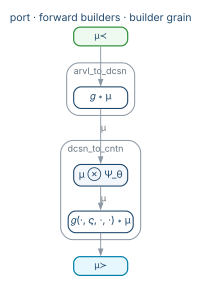

In [18]:
port.builder.fwd.diagram()

The measure on capital enters at the top, carries the two shocks after the extension, $\mu(\mathrm{k}_d, \Psi, \theta)$, and leaves as a measure on next year's resources alone, `m_next`.

`checkout.explore` with `graph="forward"` shows the forward builders graph in [Google's Model Explorer](https://github.com/google-ai-edge/model-explorer), an interactive viewer in which each builder is a frame opened to the operations it holds, and in which selecting an operation, the extension or a push-forward, shows, in a side panel, its kernel, its method once one is bound, and the measures it reads and writes, each with its perch and its type. The drawing above is the picture saved with the lesson, since the view opens only when the lesson is run: the saved output of the next cell is the paths of the two files it writes into the folder `model-explorer` beside the lesson.

In [19]:
checkout.explore(port, graph="forward")

tutorials/getting-started/model-explorer/port.graph.json
tutorials/getting-started/model-explorer/port.edge-overlays.json
